# Prediksi Harga Jual Mobil Bekas
---
## 1. Business Understanding

### 1.1 Latar Belakang, Masalah, dan Solusi
1. **Latar Belakang**: Sebuah perusahaan atau platform jual beli kendaraan ingin membangun sistem kecerdasan buatan berbasis Machine Learning untuk memperkirakan harga jual mobil bekas secara otomatis berdasarkan karakteristik kendaraan dan kondisi penggunaannya.
2. **Masalah**: Platform tesebut masih mengestimasi harga jual mobil bekas secara manual. yang membuat pendapatan platform tersebut menjadi tidak maksimal.
3. **Solusi**: Membangun model *machine learning* dengan algoritma **Decision Tree**.

### 1.2 Deskripsi Kolom Dataset `cardekho_data.csv`
| **Nama Kolom** | **Tipe Data** | **Deskripsi** |
| :-- | :-- | :-- |
| `Car_Name` | `str` | Nama atau model kendaraan yang dijual. |
| `Year` | `int64` | Tahun produksi kendaraan. |
| `Selling_Price` | `float64` | Nilai harga jual kendaraan |
| `Present_Price` | `float64` | Harga kendaraan saat ini berdasarkan data yang tersedia. |
| `Kms_Driven` | `int64` | Jarak tempuh kendaraan. |
| `Fuel_Type` | `str` | Jenis bahan bakar yang digunakan kendaraan (Petrol, Diesel, CNG). |
| `Seller_Type` | `str` | Jenis penjual kendaraan (Dealer atau Individual). |
| `Transmission` | `str` | Jenis transmisi kendaraan (Manual atau Automatic). |
| `Owner` | `int64` | Informasi jumlah atau kategori kepemilikan sebelumnya berdasarkan nilai yang tercatat dalam dataset. |


---
## 2. Data Preparation

### 2.1 Import Library

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import tkinter as tk

### 2.2 Load Dataset

In [2]:
df = pd.read_csv('cardekho_data.csv', sep=r'\s*,\s*', engine='python')
df.columns = df.columns.str.strip()

### 2.3 Tampilkan Data Teratas dan Data Terbawah

In [3]:
df.head()

,Car_Name,Year,Selling_Price,Present_Price,Kms_Driven,Fuel_Type,Seller_Type,Transmission,Owner
0,ritz,2014,3.35,5.59,27000,Petrol,Dealer,Manual,0
1,sx4,2013,4.75,9.54,43000,Diesel,Dealer,Manual,0
2,ciaz,2017,7.25,9.85,6900,Petrol,Dealer,Manual,0
3,wagon r,2011,2.85,4.15,5200,Petrol,Dealer,Manual,0
4,swift,2014,4.60,6.87,42450,Diesel,Dealer,Manual,0


In [4]:
df.tail()

,Car_Name,Year,Selling_Price,Present_Price,Kms_Driven,Fuel_Type,Seller_Type,Transmission,Owner
296,city,2016,9.50,11.6,33988,Diesel,Dealer,Manual,0
297,brio,2015,4.00,5.9,60000,Petrol,Dealer,Manual,0
298,city,2009,3.35,11.0,87934,Petrol,Dealer,Manual,0
299,city,2017,11.50,12.5,9000,Diesel,Dealer,Manual,0
300,brio,2016,5.30,5.9,5464,Petrol,Dealer,Manual,0


### 2.4 Tampilkan Informasi Data

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 301 entries, 0 to 300
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Car_Name       301 non-null    str    
 1   Year           301 non-null    int64  
 2   Selling_Price  301 non-null    float64
 3   Present_Price  301 non-null    float64
 4   Kms_Driven     301 non-null    int64  
 5   Fuel_Type      301 non-null    str    
 6   Seller_Type    301 non-null    str    
 7   Transmission   301 non-null    str    
 8   Owner          301 non-null    int64  
dtypes: float64(2), int64(3), str(4)
memory usage: 21.3 KB


### 2.5 Memeriksa Dimensi Data, Jumlah Datam Missing Value, dan Data Duplikat

In [6]:
print(f'Dimensi Data: {df.shape}')
print(f'JUmlah Data: {df.size}')

print(f'\nJumlah Missing Value: {df.isnull().sum().sum()}')
print(f'==== Missing Value Pada Setiap Kolom ==== \n{df.isnull().sum()[df.isnull().sum() > 0]}')

print(f'\nJumlah Data Duplikat: {df.duplicated().sum()}')

Dimensi Data: (301, 9)
JUmlah Data: 2709

Jumlah Missing Value: 0
==== Missing Value Pada Setiap Kolom ==== 
Series([], dtype: int64)

Jumlah Data Duplikat: 2


---
## 3. Exploratory Data Analysis (EDA)

### 3.1 Tampilkan Deskripsi Data

In [7]:
df.describe()

,Year,Selling_Price,Present_Price,Kms_Driven,Owner
count,301.000000,301.000000,301.000000,301.000000,301.000000
mean,2013.627907,4.661296,7.628472,36947.205980,0.043189
std,2.891554,5.082812,8.644115,38886.883882,0.247915
min,2003.000000,0.100000,0.320000,500.000000,0.000000
25%,2012.000000,0.900000,1.200000,15000.000000,0.000000
50%,2014.000000,3.600000,6.400000,32000.000000,0.000000
75%,2016.000000,6.000000,9.900000,48767.000000,0.000000
max,2018.000000,35.000000,92.600000,500000.000000,3.000000


### 3.2 Analisis Outlier dengan IQR & Z-Score Pada Kolom Numerik


In [8]:
outliers = []

numeric_columns = df.select_dtypes(include=[np.number]).columns.tolist()

for col in numeric_columns:
  if col in df.columns:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    mean = df[col].mean()
    median = df[col].median()
    std = df[col].std()
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    outlier_iqr = df[(df[col] < lower) | (df[col] > upper)]
    z_score = (df[col] - mean) / std
    outlier_z_score = df[np.abs(z_score) > 3]
    
    outliers.append({
      'Kolom' : col,
      'Mean' : mean,
      'Standarisasi' : std,
      'Min' : df[col].min(),
      'Q1' : q1,
      'Median' : median,
      'Q3' : q3,
      'Max' : df[col].max(),
      'Batas Bawah IQR' : lower,
      'Batas Atas IQR' : upper,
      'Jumlah Outlier IQR' : outlier_iqr.shape[0],
      'Jumlah Outlier Z-Score' : outlier_z_score.shape[0]
    })
    
pd.DataFrame(outliers)

,Kolom,Mean,Standarisasi,Min,Q1,Median,Q3,Max,Batas Bawah IQR,Batas Atas IQR,Jumlah Outlier IQR,Jumlah Outlier Z-Score
0,Year,2013.627907,2.891554,2003.00,2012.0,2014.0,2016.0,2018.0,2006.00,2022.00,7,3
1,Selling_Price,4.661296,5.082812,0.10,0.9,3.6,6.0,35.0,-6.75,13.65,17,8
2,Present_Price,7.628472,8.644115,0.32,1.2,6.4,9.9,92.6,-11.85,22.95,14,5
3,Kms_Driven,36947.205980,38886.883882,500.00,15000.0,32000.0,48767.0,500000.0,-35650.50,99417.50,8,3
4,Owner,0.043189,0.247915,0.00,0.0,0.0,0.0,3.0,0.00,0.00,11,11


### 3.3 Visualisasi Outlier Dengan Boxplot

Text(0.5, 1.0, 'Visualisasi outlier dengan boxplot')

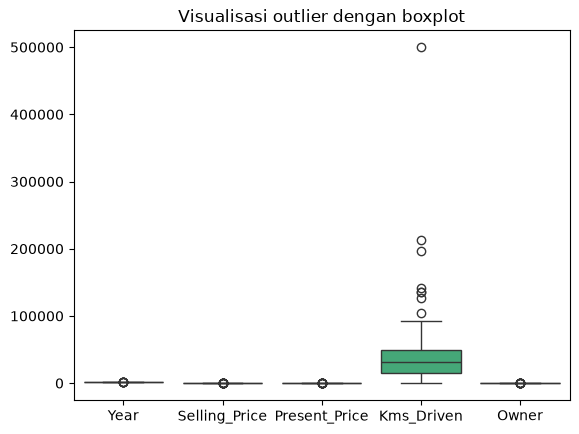

In [9]:
sns.boxplot(data=df, palette='viridis')
plt.title('Visualisasi outlier dengan boxplot')

**Insigt**: Grafik boxplot tersebut menunjukkan bahwa Kms_Driven memiliki rentang nilai (skala) yang jauh lebih besar dibandingkan fitur numerik lainnya, serta memuat banyak outlier ekstrem hingga mencapai 500.000 km.

### 3.4 Visualisasi DIstribusi Data

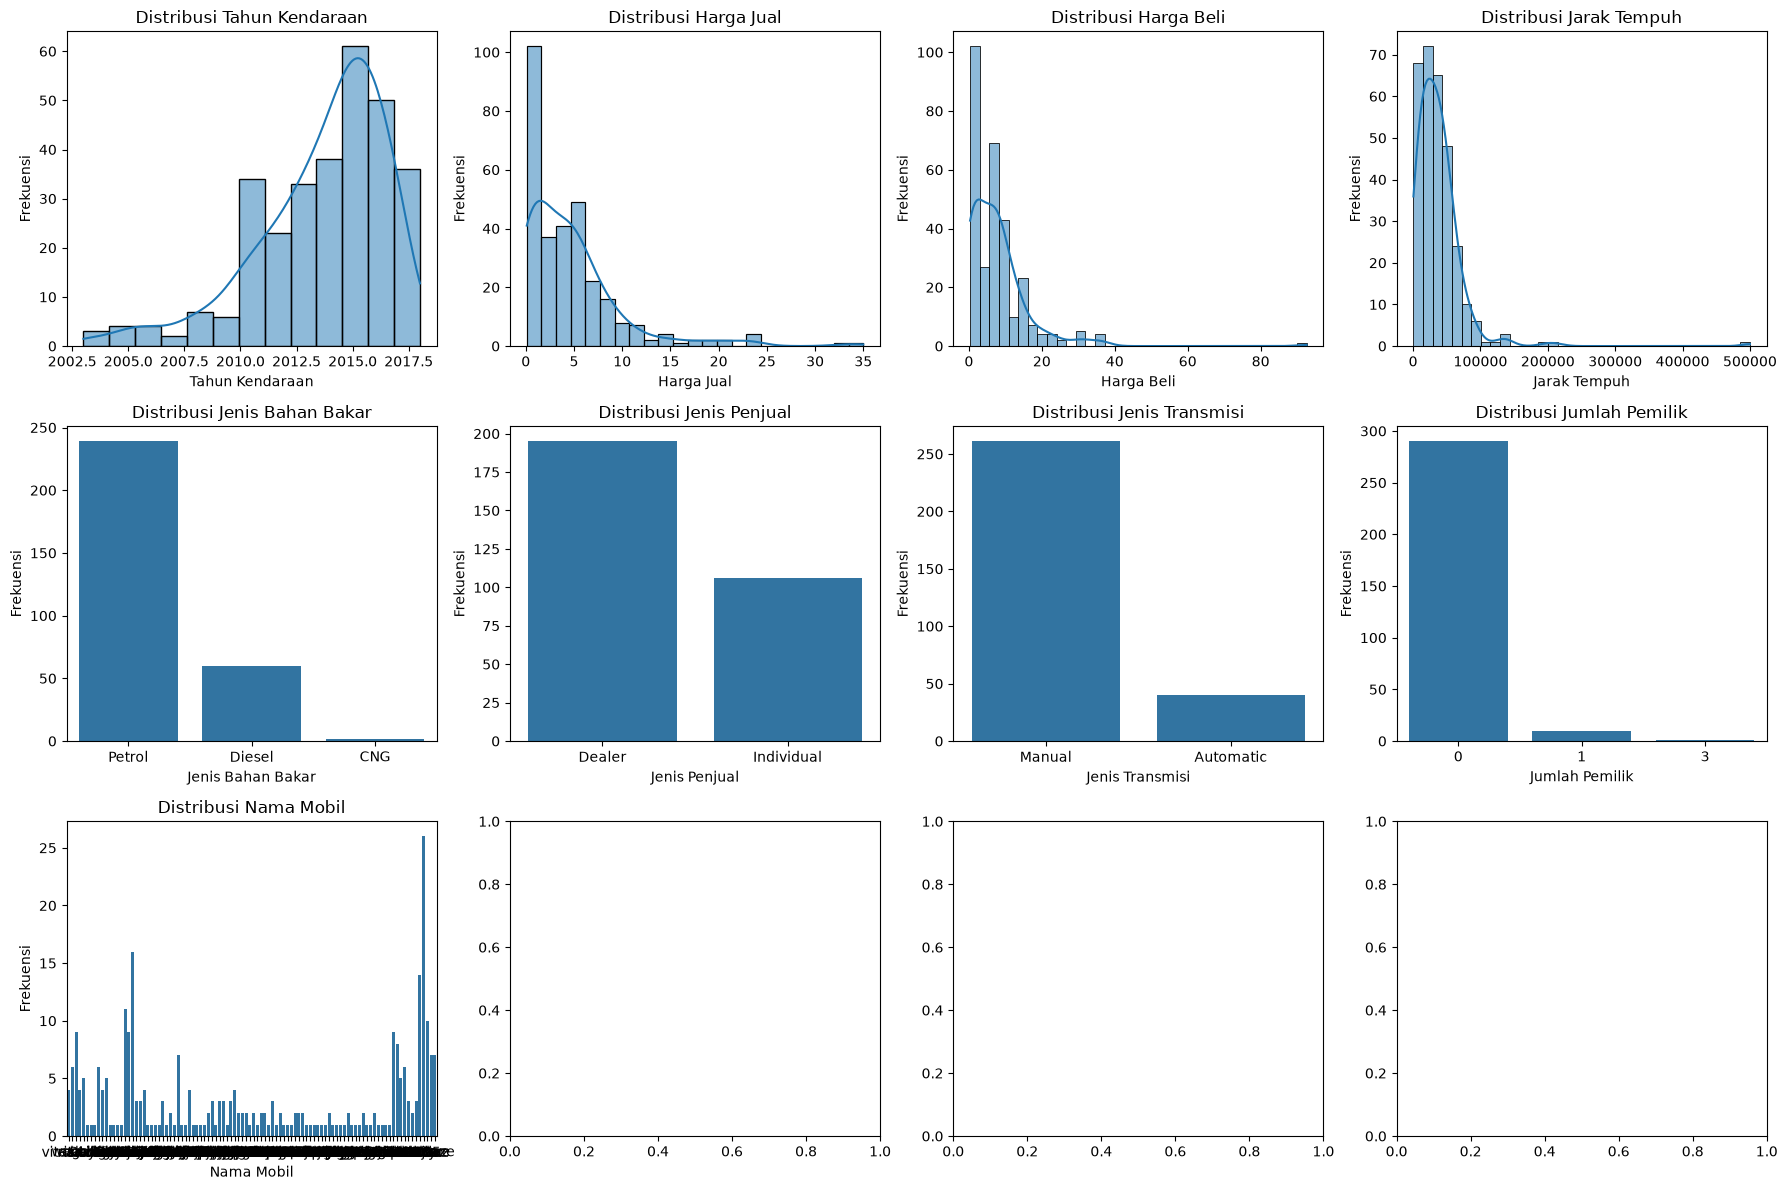

In [10]:
figure, axes = plt.subplots(3, 4, figsize=(18, 12))

sns.histplot(data=df, x='Year', kde=True, ax=axes[0, 0])
axes[0, 0].set_title('Distribusi Tahun Kendaraan')
axes[0, 0].set_xlabel('Tahun Kendaraan')
axes[0, 0].set_ylabel('Frekuensi')

sns.histplot(data=df, x='Selling_Price', kde=True, ax=axes[0, 1])
axes[0, 1].set_title('Distribusi Harga Jual')
axes[0, 1].set_xlabel('Harga Jual')
axes[0, 1].set_ylabel('Frekuensi')

sns.histplot(data=df, x='Present_Price', kde=True, ax=axes[0, 2])
axes[0, 2].set_title('Distribusi Harga Beli')
axes[0, 2].set_xlabel('Harga Beli')
axes[0, 2].set_ylabel('Frekuensi')

sns.histplot(data=df, x='Kms_Driven', kde=True, ax=axes[0, 3])
axes[0, 3].set_title('Distribusi Jarak Tempuh')
axes[0, 3].set_xlabel('Jarak Tempuh')
axes[0, 3].set_ylabel('Frekuensi')

sns.countplot(data=df, x='Fuel_Type', ax=axes[1, 0])
axes[1, 0].set_title('Distribusi Jenis Bahan Bakar')
axes[1, 0].set_xlabel('Jenis Bahan Bakar')
axes[1, 0].set_ylabel('Frekuensi')

sns.countplot(data=df, x='Seller_Type', ax=axes[1, 1])
axes[1, 1].set_title('Distribusi Jenis Penjual')
axes[1, 1].set_xlabel('Jenis Penjual')
axes[1, 1].set_ylabel('Frekuensi')

sns.countplot(data=df, x='Transmission', ax=axes[1, 2])
axes[1, 2].set_title('Distribusi Jenis Transmisi')
axes[1, 2].set_xlabel('Jenis Transmisi')
axes[1, 2].set_ylabel('Frekuensi')

sns.countplot(data=df, x='Owner', ax=axes[1, 3])
axes[1, 3].set_title('Distribusi Jumlah Pemilik')
axes[1, 3].set_xlabel('Jumlah Pemilik')
axes[1, 3].set_ylabel('Frekuensi')

sns.countplot(data=df, x='Car_Name', ax=axes[2, 0])
axes[2, 0].set_title('Distribusi Nama Mobil')
axes[2, 0].set_xlabel('Nama Mobil')
axes[2, 0].set_ylabel('Frekuensi')

plt.tight_layout()
plt.show()

**Insigt**: Sebagian besar kendaraan didominasi oleh mobil keluaran terbaru (sekitar 2015–2017) berbahan bakar bensin, bertransmisi manual, belum pernah berpindah tangan (pemilik ke-0), serta dijual oleh dealer dengan kisaran harga dan jarak tempuh yang cenderung rendah.

### 3.5 Analisis Korelasi Dengan Pearson, Spearman, dan Kendall

In [11]:
var_list = ['Year', 'Selling_Price', 'Present_Price', 'Kms_Driven', 'Owner']

for col in var_list:
  df[col] = pd.to_numeric(df[col], errors='coerce')

korelasi_list = []

for i in range(len(var_list)) :
  for j in range(i + 1, len(var_list)) :
    var1 = var_list[i]
    var2 = var_list[j]
    
    clean_df = df[[var1, var2]].dropna()
    
    pearson_corr = clean_df[var1].corr(clean_df[var2], method='pearson')
    spearman_corr = clean_df[var1].corr(clean_df[var2], method='spearman')
    kendall_corr = clean_df[var1].corr(clean_df[var2], method='kendall')
    
    korelasi_list.append({
      'pasangan variabel': f'{var1} vs {var2}',
      'pearson correlation': pearson_corr,
      'spearman correlation': spearman_corr,
      'kendall correlation': kendall_corr
    })
    
pd.DataFrame(korelasi_list)

,pasangan variabel,pearson correlation,spearman correlation,kendall correlation
0,Year vs Selling_Price,0.236141,0.282620,0.218798
1,Year vs Present_Price,-0.047584,-0.010963,-0.004108
2,Year vs Kms_Driven,-0.524342,-0.633085,-0.486466
3,Year vs Owner,-0.182104,-0.138104,-0.119523
4,Selling_Price vs Present_Price,0.878983,0.908251,0.763834
5,Selling_Price vs Kms_Driven,0.029187,0.146343,0.089347
6,Selling_Price vs Owner,-0.088344,-0.144264,-0.118214
7,Present_Price vs Kms_Driven,0.203647,0.376546,0.263296
8,Present_Price vs Owner,0.008057,-0.100324,-0.082616
9,Kms_Driven vs Owner,0.089216,0.023536,0.019261


### 3.6 Visualisasi Korelasi Dengan Heatmap

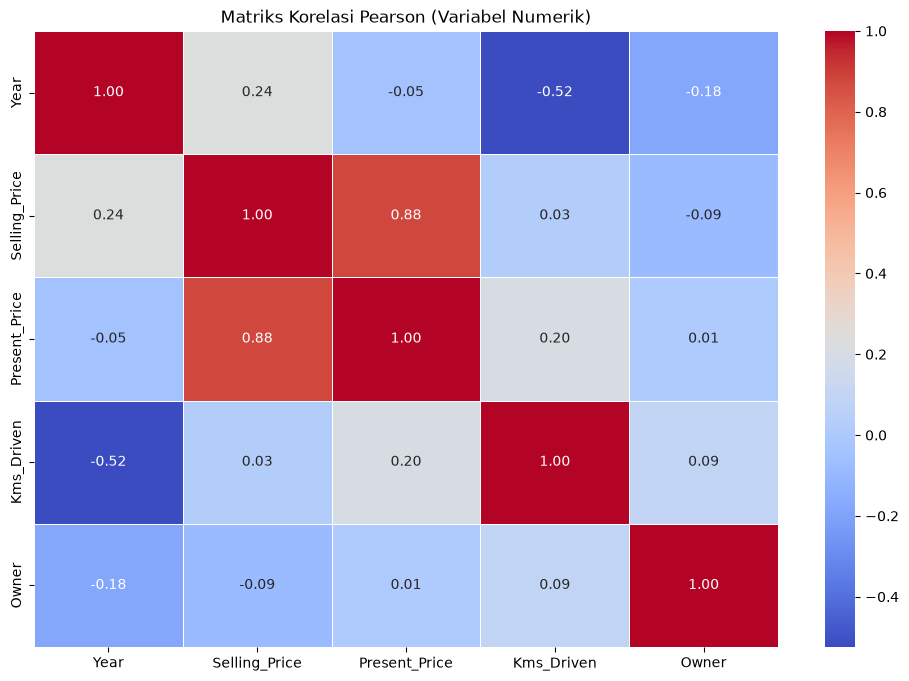

In [12]:
numeric_df = df.select_dtypes(include=[np.number]).drop(columns=['Id'], errors='ignore')

corr_matrix = numeric_df.corr(method='pearson')
plt.figure(figsize=(12, 8))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Matriks Korelasi Pearson (Variabel Numerik)')
plt.show()

**Insigt**: Terdapat hubungan positif yang sangat kuat antara Selling_Price dan Present_Price, serta korelasi negatif moderat antara Year dan Kms_Driven, sedangkan fitur-fitur lainnya cenderung tidak memiliki korelasi linier yang signifikan.

In [16]:
def predict_price():
    prediction_label.configure(text_color=("black", "white"))

    car_name = entryCarName.get()
    year_val = entryYear.get().strip()
    present_price_val = entryPresentPrice.get().strip()
    kms_driven_val = entryKmsDriven.get().strip()
    fuel_type = entryFuelType.get()
    seller_type = entrySellerType.get()
    transmission = entryTransmission.get()
    owner_val = entryOwner.get().strip()

    if not all([car_name, year_val, present_price_val, kms_driven_val, fuel_type, seller_type, transmission, owner_val]):
        prediction_label.configure(
            text="Peringatan: Harap isi semua kolom input terlebih dahulu!",
            text_color="red"
        )
        return

    try:
        year = int(year_val)
        present_price = float(present_price_val)
        kms_driven = int(kms_driven_val)
        owner = int(owner_val)
    except ValueError:
        prediction_label.configure(
            text="Error: Tahun, Harga Beli, Jarak Tempuh, dan Pemilik harus berupa angka!",
            text_color="red"
        )
        return

    fuel_map = {'Petrol': 0, 'Diesel': 1, 'CNG': 2}
    seller_map = {'Dealer': 0, 'Individual': 1}
    trans_map = {'Manual': 0, 'Automatic': 1}

    try:
        fuel_encoded = fuel_map[fuel_type]
        seller_encoded = seller_map[seller_type]
        trans_encoded = trans_map[transmission]
    except KeyError as e:
        prediction_label.configure(
            text=f"Error: Pilihan {e} tidak valid!",
            text_color="red"
        )
        return

    features = pd.DataFrame([[
        year, 
        present_price, 
        kms_driven, 
        fuel_encoded, 
        seller_encoded, 
        trans_encoded, 
        owner
    ]], columns=['Year', 'Present_Price', 'Kms_Driven', 'Fuel_Type', 'Seller_Type', 'Transmission', 'Owner'])

    try:
        predicted_value = model.predict(features)[0]

        prediction_label.configure(
            text=f"Prediksi Harga Jual Mobil Bekas: {predicted_value:.2f}",
            text_color=("black", "white")
        )
    except Exception as e:
        prediction_label.configure(
            text=f"Error Prediksi: {str(e)}",
            text_color="red"
        )

In [14]:
trans_map = {'Manual': 0, 'Automatic': 1}
fuel_map = {'Petrol': 0, 'Diesel': 1, 'CNG': 2}
seller_map = {'Dealer': 0, 'Individual': 1}

In [15]:
from customtkinter import *

app = CTk()
app.title("Prediksi Harga Jual Mobil Bekas")

lebar = 500
tinggi = 700
screen_width = app.winfo_screenwidth()
screen_height = app.winfo_screenheight()
x = int((screen_width / 2) - (lebar / 2) -75)
y = int((screen_height / 2) - (tinggi / 2) - 100)
app.geometry(f"{lebar}x{tinggi}+{x}+{y}")
set_appearance_mode("light")

Title = CTkLabel(app, text="Prediksi Harga Jual Mobil Bekas", font=("Arial", 20, "bold"))
Title.pack(pady=(20, 5))

mainFrame = CTkScrollableFrame(master=app, fg_color="#fff", corner_radius=12)
mainFrame.pack(pady=10, padx=20, fill="both", expand=True)

lblCarName = CTkLabel(master=mainFrame, text="Nama Mobil", font=("Arial", 14, "bold"), fg_color="transparent", justify="left")
lblCarName.pack(pady=5, padx=10, anchor="w")
entryCarName = CTkComboBox(master=mainFrame, values=df['Car_Name'].unique().tolist(), font=("Arial", 14))
entryCarName.pack(pady=(0, 10), anchor="w", padx=10, fill="x")

lblYear = CTkLabel(master=mainFrame, text="Tahun Produksi Mobil", font=("Arial", 14, "bold"), fg_color="transparent", justify="left")
lblYear.pack(pady=5, padx=10, anchor="w")
entryYear = CTkEntry(master=mainFrame, placeholder_text="e.g. 2015", font=("Arial", 14))
entryYear.pack(pady=(0, 10), anchor="w", padx=10, fill="x")

lblPresentPrice = CTkLabel(master=mainFrame, text="Harga Beli Mobil", font=("Arial", 14, "bold"), fg_color="transparent", justify="left")
lblPresentPrice.pack(pady=5, padx=10, anchor="w")
entryPresentPrice = CTkEntry(master=mainFrame, placeholder_text="e.g. 5.5", font=("Arial", 14))
entryPresentPrice.pack(pady=(0, 10), anchor="w", padx=10, fill="x")

lblKmsDriven = CTkLabel(master=mainFrame, text="Jarak Tempuh Mobil (dalam km)", font=("Arial", 14, "bold"), fg_color="transparent", justify="left")
lblKmsDriven.pack(pady=5, padx=10, anchor="w")
entryKmsDriven = CTkEntry(master=mainFrame, placeholder_text="e.g. 50000", font=("Arial", 14))
entryKmsDriven.pack(pady=(0, 10), anchor="w", padx=10, fill="x")

lblFuelType = CTkLabel(master=mainFrame, text="Jenis Bahan Bakar", font=("Arial", 14, "bold"), fg_color="transparent", justify="left")
lblFuelType.pack(pady=5, padx=10, anchor="w")
entryFuelType = CTkComboBox(master=mainFrame, values=list(fuel_map.keys()), font=("Arial", 14))
entryFuelType.pack(pady=(0, 10), anchor="w", padx=10, fill="x")

lblSellerType = CTkLabel(master=mainFrame, text="Jenis Penjual", font=("Arial", 14, "bold"), fg_color="transparent", justify="left")
lblSellerType.pack(pady=5, padx=10, anchor="w")
entrySellerType = CTkComboBox(master=mainFrame, values=list(seller_map.keys()), font=("Arial", 14))
entrySellerType.pack(pady=(0, 10), anchor="w", padx=10, fill="x")

lblTransmission = CTkLabel(master=mainFrame, text="Jenis Transmisi", font=("Arial", 14, "bold"), fg_color="transparent", justify="left")
lblTransmission.pack(pady=5, padx=10, anchor="w")
entryTransmission = CTkComboBox(master=mainFrame, values=list(trans_map.keys()), font=("Arial", 14))
entryTransmission.pack(pady=(0, 10), anchor="w", padx=10, fill="x")

lblOwner = CTkLabel(master=mainFrame, text="Jumlah Pemilik", font=("Arial", 14, "bold"), fg_color="transparent", justify="left")
lblOwner.pack(pady=5, padx=10, anchor="w")
entryOwner = CTkEntry(master=mainFrame, placeholder_text="e.g. 1", font=("Arial", 14))
entryOwner.pack(pady=(0, 10), anchor="w", padx=10, fill="x")

btn = CTkButton(master=app, text="Prediksi Harga Jual", font=("Arial", 14, "bold"), command=predict_price)
btn.pack(pady=(10, 20), fill="x", padx=20)

prediction_label = CTkLabel(master=app, text="Prediksi Harga Jual Mobil Bekas: -", font=("Arial", 14, "bold"), fg_color="transparent", justify="left")
prediction_label.pack(pady=(10, 20), padx=20, anchor="w")

app.mainloop()

---

## 4. Data Preprocessing

### 4.1 Checking and Handle Missing Value and Data Duplicated

In [ ]:
print("--- Missing Value ---")
print(df.isnull().sum())
print("\n--- Data Duplicated ---")
print(df[df.duplicated()])

In [ ]:
df = df.drop_duplicates()
print(f"Data Duplicated After Handling: {df.duplicated().sum()}")

### 4.2 One-Hot Encoding

In [ ]:
df = df.drop(columns=['Car_Name'])

categorical = ['Fuel_Type', 'Seller_Type', 'Transmission']
df = pd.get_dummies(df, columns=categorical, dtype=int)
df.head(10)

### 4.3 Split Data Training and Testing

In [11]:
X = df.drop(columns=['Selling_Price'])
y = df['Selling_Price']

print(f"X : {X.shape[0]} baris, {X.shape[1]} kolom")
print(f"y : {len(y)} label")

np.random.seed(43)
index = np.random.permutation(len(X))
split = int(0.8 * len(X))

X_train = X.iloc[index[:split]]
X_test = X.iloc[index[split:]]
y_train = y.iloc[index[:split]]
y_test = y.iloc[index[split:]]

print(f"Training Data: {len(X_train)} ({len(X_train)/len(X)*100:.0f}%)")
print(f"Testing Data: {len(X_test)} ({len(X_test)/len(X)*100:.0f}%)")

X : 299 baris, 11 kolom
y : 299 label
Training Data: 239 (80%)
Testing Data: 60 (20%)


---

## 5. Modelling

### 5.1 Class Structure Node and Cart

In [13]:
class Node:
    def __init__(self, feature=None, threshold=None, left=None, right=None, value=None, mse=None, n_samples=None):
        self.feature = feature
        self.threshold = threshold
        self.left = left
        self.right = right
        self.value = value
        self.mse = mse
        self.n_samples = n_samples

    @property
    def is_leaf(self):
        return self.value is not None


class Cart:
    def __init__(self, max_depth=5, min_samples_split=5, min_samples_leaf=2):
        self.max_depth = max_depth
        self.min_samples_split = min_samples_split
        self.min_samples_leaf = min_samples_leaf
        self.root = None

    def _calculate_mse(self, y):
        if len(y) == 0:
            return 0.0
        return np.mean((y - np.mean(y)) ** 2)

    def fit(self, X, y):
        X_mat = X.values if isinstance(X, pd.DataFrame) else np.array(X)
        y_vec = y.values if isinstance(y, pd.Series) else np.array(y)
        self.root = self._build_tree(X_mat, y_vec, depth=0)

    def _build_tree(self, X, y, depth=0):
        n_samples, n_features = X.shape
        node_mse = self._calculate_mse(y)
        node_value = np.mean(y)

        if (depth >= self.max_depth or n_samples < self.min_samples_split or node_mse == 0.0):
            return Node(value=node_value, mse=node_mse, n_samples=n_samples)

        best_feature, best_threshold = None, None
        best_cost = float('inf')

        for feat_index in range (n_features):
            col_values = X[:, feat_index]
            threshold = np.unique(col_values)

            for thresh in threshold:
                left_mask = col_values <= thresh
                right_mask = ~left_mask

                n_left, n_right = np.sum(left_mask), np.sum(right_mask)
                if n_left < self.min_samples_leaf or n_right < self.min_samples_leaf:
                    continue

                mse_left = self._calculate_mse(y[left_mask])
                mse_right = self._calculate_mse(y[right_mask])
                cost = (n_left * mse_left + n_right * mse_right) / n_samples

                if cost < best_cost:
                    best_cost = cost
                    best_feature = feat_index
                    best_threshold = thresh

        if best_feature is None:
            return Node(value=node_value, mse=node_mse, n_samples=n_samples)

        left_mask = X[:, best_feature] <= best_threshold
        right_mask = ~left_mask

        left_subtree = self._build_tree(X[left_mask], y[left_mask], depth + 1)
        right_subtree = self._build_tree(X[right_mask], y[right_mask], depth + 1)

        return Node(feature=best_feature, threshold=best_threshold, left=left_subtree, right=right_subtree, mse=node_mse, n_samples=n_samples)

    def predict (self, X):
        X_mat = X.values if isinstance(X, pd.DataFrame) else np.array(X)
        return np.array([self._traverse_tree(row, self.root) for row in X_mat])

    def _traverse_tree(self, row, node):
        if node.is_leaf:
            return node.value
        if row[node.feature] <= node.threshold:
            return self._traverse_tree(row, node.left)
        return self._traverse_tree(row, node.right)

### 5.2 Training Model and Prediction

In [14]:
model_cart = Cart(max_depth=5, min_samples_split=5, min_samples_leaf=2)
model_cart.fit(X_train, y_train)

y_train_pred = model_cart.predict(X_train)
y_test_pred = model_cart.predict(X_test)

### 5.3 Show Logic Tree Structure

In [17]:
def print_tree_structure(node, feature_names, indent=""):
    if node.is_leaf:
        print(f"{indent}└── [Leaf] Prediksi: {node.value:.2f} (samples: {node.n_samples}, MSE: {node.mse:.2f})")
        return

    feat = feature_names[node.feature]
    print(f"{indent}├── [{feat} <= {node.threshold:.2f}] (samples: {node.n_samples}, MSE: {node.mse:.2f})")
    print(f"{indent}│   [True]")
    print_tree_structure(node.left, feature_names, indent + "│   ")
    print(f"{indent}│   [False]")
    print_tree_structure(node.right, feature_names, indent + "    ")

print_tree_structure(model_cart.root, X_train.columns.tolist())

├── [Present_Price <= 22.83] (samples: 239, MSE: 21.86)
│   [True]
│   ├── [Present_Price <= 5.59] (samples: 231, MSE: 11.11)
│   │   [True]
│   │   ├── [Present_Price <= 2.69] (samples: 107, MSE: 0.97)
│   │   │   [True]
│   │   │   ├── [Present_Price <= 1.20] (samples: 85, MSE: 0.15)
│   │   │   │   [True]
│   │   │   │   ├── [Present_Price <= 0.79] (samples: 63, MSE: 0.04)
│   │   │   │   │   [True]
│   │   │   │   │   └── [Leaf] Prediksi: 0.33 (samples: 33, MSE: 0.02)
│   │   │   │   │   [False]
│   │   │   │       └── [Leaf] Prediksi: 0.58 (samples: 30, MSE: 0.03)
│   │   │   │   [False]
│   │   │       ├── [Kms_Driven <= 4000.00] (samples: 22, MSE: 0.04)
│   │   │       │   [True]
│   │   │       │   └── [Leaf] Prediksi: 1.62 (samples: 3, MSE: 0.02)
│   │   │       │   [False]
│   │   │           └── [Leaf] Prediksi: 1.13 (samples: 19, MSE: 0.01)
│   │   │   [False]
│   │       ├── [Kms_Driven <= 57000.00] (samples: 22, MSE: 0.31)
│   │       │   [True]
│   │       │   ├── [Year 

---

## 6. Evaluation

### 6.1 Evaluation Result Analysis 

In [24]:
def evaluate_regression(y_true, y_pred):
    y_true = np.array(y_true)
    y_pred = np.array(y_pred)
    
    mae = np.mean(np.abs(y_true - y_pred))
    mse = np.mean((y_true - y_pred) ** 2)
    rmse = np.sqrt(mse)
    
    ss_res = np.sum((y_true - y_pred) ** 2)
    ss_tot = np.sum((y_true - np.mean(y_true)) ** 2)
    r2 = 1 - (ss_res / ss_tot)
    
    return {'MAE': mae, 'MSE': mse, 'RMSE': rmse, 'R2': r2}

train_metrics = evaluate_regression(y_train, y_train_pred)
test_metrics = evaluate_regression(y_test, y_test_pred)

df_eval = pd.DataFrame([train_metrics, test_metrics], index=['Training Set', 'Testing Set'])
print(df_eval.round(4))

print(f"\n1. R-squared (R²) Data Latih : {train_metrics['R2']*100:.2f}%")
print(f"2. R-squared (R²) Data Uji   : {test_metrics['R2']*100:.2f}%")
print(f"3. Rata-rata Error (MAE)     : {test_metrics['MAE']:.2f}")
print(f"4. Root Mean Squared Error   : {test_metrics['RMSE']:.2f}")

                 MAE      MSE    RMSE      R2
Training Set  0.5901   0.8973  0.9472  0.9589
Testing Set   1.8663  14.9476  3.8662  0.5843

1. R-squared (R²) Data Latih : 95.89%
2. R-squared (R²) Data Uji   : 58.43%
3. Rata-rata Error (MAE)     : 1.87
4. Root Mean Squared Error   : 3.87


### 6.2 Ratio Table Actual and Prediction

In [26]:
df_comparison = pd.DataFrame({
    'Actual Selling Price': y_test.values,
    'Predicted Selling Price': np.round(y_test_pred, 2),
    'Absolute Error': np.round(np.abs(y_test.values - y_test_pred), 2)
})

df_comparison.head(10)

,Actual Selling Price,Predicted Selling Price,Absolute Error
0,1.95,2.69,0.74
1,6.70,5.04,1.66
2,0.80,0.58,0.22
3,2.90,2.70,0.20
4,2.55,3.11,0.56
5,5.20,5.04,0.16
6,12.90,10.08,2.82
7,3.49,9.45,5.96
8,2.25,2.70,0.45
9,35.00,14.70,20.30


### 6.3 Evaluation Model Visualization 

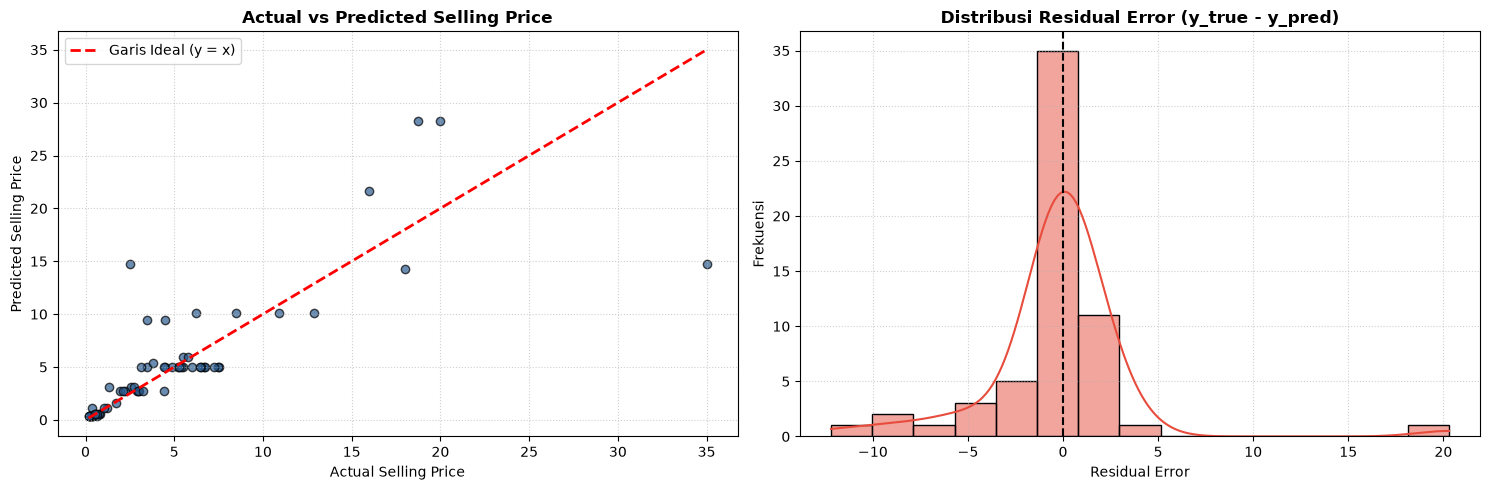

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

axes[0].scatter(y_test, y_test_pred, color='#2b5c8f', edgecolors='k', alpha=0.7)
min_val = min(y_test.min(), y_test_pred.min())
max_val = max(y_test.max(), y_test_pred.max())
axes[0].plot([min_val, max_val], [min_val, max_val], 'r--', lw=2, label='Garis Ideal (y = x)')
axes[0].set_title('Actual vs Predicted Selling Price', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Actual Selling Price')
axes[0].set_ylabel('Predicted Selling Price')
axes[0].legend()
axes[0].grid(True, linestyle=':', alpha=0.6)

residuals = y_test.values - y_test_pred
sns.histplot(residuals, kde=True, ax=axes[1], color='#e74c3c', bins=15)
axes[1].axvline(0, color='black', linestyle='--', lw=1.5)
axes[1].set_title('Distribusi Residual Error (y_true - y_pred)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Residual Error')
axes[1].set_ylabel('Frekuensi')
axes[1].grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()